# Fundamentals of Machine Learning — Exercise 8

## Dimensionality Reduction and Latent Spaces

Real datasets often contain many correlated or redundant features. Dimensionality reduction creates a smaller representation that may help us:

- visualise high-dimensional data,
- compress information,
- remove some redundancy or noise,
- prepare features for another model,
- inspect latent structure.

This exercise compares four important approaches:

- **Principal Component Analysis (PCA)**,
- **Truncated Singular Value Decomposition (SVD)**,
- **t-distributed Stochastic Neighbour Embedding (t-SNE)**,
- **Uniform Manifold Approximation and Projection (UMAP)**.

The classroom workflow remains:

> **question → prediction → computation → visualisation → interpretation → verification**

### Learning outcomes

After completing this exercise, you should be able to:

- explain what a principal component represents,
- distinguish explained variance from reconstruction quality,
- explain why scaling can change PCA,
- select a defensible number of principal components,
- reconstruct data from a lower-dimensional PCA representation,
- explain when TruncatedSVD is useful for sparse data,
- distinguish compression methods from visualisation methods,
- compare PCA, t-SNE, and UMAP cautiously,
- explain why distances and cluster sizes in t-SNE plots can be misleading,
- use local-neighbourhood evidence to audit an embedding,
- fit dimensionality reduction inside a leakage-safe modelling pipeline,
- use AI to question an interpretation after producing your own answer.

**Recommended duration:** 100–120 minutes.  
The final latent-space audit may be completed as homework.

## How to work in this exercise

Most code is already prepared. Your task is to:

1. **predict** before running a result,
2. **change** only clearly marked settings,
3. **connect** plots to a mathematical or geometric idea,
4. **compare** alternative representations,
5. **state** what cannot be concluded from a visualisation,
6. **verify** at least one visual claim numerically or in the original feature space.

A beautiful two-dimensional plot is not automatically a faithful map of the original data.

## 0. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits, load_wine
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE, trustworthiness
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

## 1. PCA begins with a direction of maximum variance

Consider a two-dimensional dataset whose features are strongly correlated.

Before running the cell, predict:

1. In which direction does the cloud vary most? along the diagonal line
2. Would a horizontal or vertical one-dimensional projection preserve the data well? neither would be optimal, both discard the strong linear relationship
3. What direction would you choose if only one coordinate could be retained? PC1

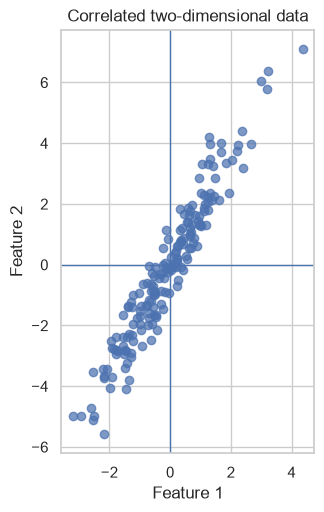

In [2]:
rng = np.random.default_rng(RANDOM_STATE)

x1 = rng.normal(0, 1.5, 180)
x2 = 1.8 * x1 + rng.normal(0, 0.65, 180)
X_geometry = np.column_stack([x1, x2])

plt.figure(figsize=(7, 5.5))
plt.scatter(X_geometry[:, 0], X_geometry[:, 1], alpha=0.72)
plt.axhline(0, linewidth=1)
plt.axvline(0, linewidth=1)
plt.gca().set_aspect('equal', adjustable='box')
plt.title('Correlated two-dimensional data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

### Compute the principal directions from the covariance matrix

For centred data, PCA finds eigenvectors of the covariance matrix.

- The first eigenvector points in the direction of maximum variance.
- The second eigenvector is orthogonal to the first.
- Eigenvalues quantify variance along those directions.

In [3]:
X_centered = X_geometry - X_geometry.mean(axis=0)
covariance_matrix = np.cov(X_centered, rowvar=False)

eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

manual_variance_ratio = eigenvalues / eigenvalues.sum()

print('Covariance matrix:')
display(pd.DataFrame(covariance_matrix, index=['Feature 1', 'Feature 2'], columns=['Feature 1', 'Feature 2']).round(3))

print('Explained variance ratio:')
display(pd.Series(manual_variance_ratio, index=['PC1', 'PC2']).round(3))

Covariance matrix:


,Feature 1,Feature 2
Feature 1,1.693,2.989
Feature 2,2.989,5.714


Explained variance ratio:


PC1    0.986
PC2    0.014
dtype: float64

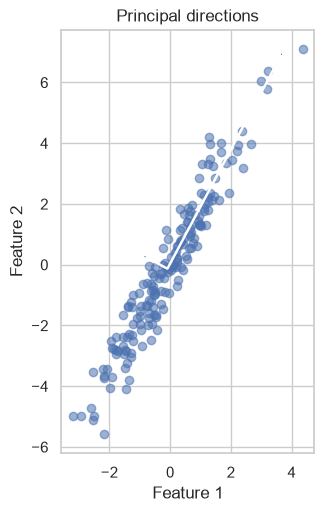

In [4]:
mean_point = X_geometry.mean(axis=0)
scale = 3.0

plt.figure(figsize=(7, 5.5))
plt.scatter(X_geometry[:, 0], X_geometry[:, 1], alpha=0.55)

for component_index in range(2):
    direction = eigenvectors[:, component_index]
    length = scale * np.sqrt(eigenvalues[component_index])
    plt.arrow(
        mean_point[0],
        mean_point[1],
        direction[0] * length,
        direction[1] * length,
        width=0.035,
        length_includes_head=True,
        label=f'PC{component_index + 1}',
    )

plt.gca().set_aspect('equal', adjustable='box')
plt.title('Principal directions')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

### Activity 1 — Interpret the geometry

Complete the explanation:

> PC1 points approximately _____along the diagonal line_____ because _____it captures the direction of maximum data spread where the two features are strongly correlated_____.
>
> PC1 preserves about _____98.6%_____ of the total variance.
>
> Reducing the dataset to one component loses mainly _____the minor spread to the main diagonal line_____.

Why can the sign of a principal component be reversed without changing the solution?

### Project to one dimension and reconstruct

PCA compression has two steps:

1. project observations onto the selected component,
2. reconstruct an approximation in the original feature space.

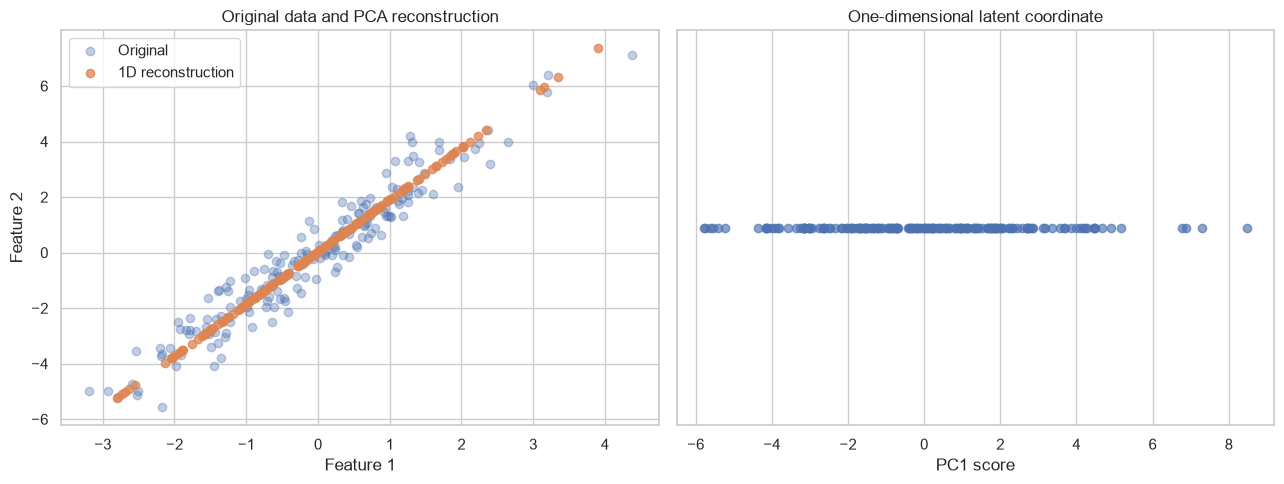

Reconstruction MSE: 0.0500


In [5]:
pca_one = PCA(n_components=1)
X_one_dimensional = pca_one.fit_transform(X_geometry)
X_reconstructed = pca_one.inverse_transform(X_one_dimensional)

reconstruction_mse = np.mean((X_geometry - X_reconstructed) ** 2)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(X_geometry[:, 0], X_geometry[:, 1], alpha=0.35, label='Original')
axes[0].scatter(X_reconstructed[:, 0], X_reconstructed[:, 1], alpha=0.75, label='1D reconstruction')
axes[0].set_title('Original data and PCA reconstruction')
axes[0].set_xlabel('Feature 1')
axes[0].set_ylabel('Feature 2')
axes[0].legend()

axes[1].scatter(X_one_dimensional[:, 0], np.zeros(len(X_one_dimensional)), alpha=0.65)
axes[1].set_title('One-dimensional latent coordinate')
axes[1].set_xlabel('PC1 score')
axes[1].set_yticks([])

plt.tight_layout()
plt.show()

print(f'Reconstruction MSE: {reconstruction_mse:.4f}')

### Verification checkpoint

Compare the original and reconstructed points.

- Which direction of variation was removed? Variation along PC2
- Does high explained variance mean perfect reconstruction? No, 1,4% of information is discarded
- What would happen if the original cloud were approximately circular? data would have uncorelated features with high variance in all directions

## 2. Scaling can change the meaning of PCA

The Wine dataset contains chemical measurements with very different units and numerical ranges.

Before running PCA, predict:

1. Which feature is likely to dominate PCA without scaling? Proline, it ranges from 278 to 1680
2. Does a large numerical variance automatically mean that a feature is scientifically more important? No, it is highly dependent on the chosen unit of measure.
3. What question does standardisation change? Which features account for the most relative statistical variance?

In [6]:
wine = load_wine(as_frame=True)
X_wine = wine.data.copy()
y_wine = wine.target.copy()

wine_scale_table = X_wine.agg(['mean', 'std', 'min', 'max']).T
wine_scale_table['range'] = wine_scale_table['max'] - wine_scale_table['min']
display(wine_scale_table.sort_values('std', ascending=False).round(2))

,mean,std,min,max,range
proline,746.89,314.91,278.00,1680.00,1402.00
magnesium,99.74,14.28,70.00,162.00,92.00
alcalinity_of_ash,19.49,3.34,10.60,30.00,19.40
color_intensity,5.06,2.32,1.28,13.00,11.72
malic_acid,2.34,1.12,0.74,5.80,5.06
flavanoids,2.03,1.00,0.34,5.08,4.74
alcohol,13.00,0.81,11.03,14.83,3.80
od280/od315_of_diluted_wines,2.61,0.71,1.27,4.00,2.73
total_phenols,2.30,0.63,0.98,3.88,2.90
proanthocyanins,1.59,0.57,0.41,3.58,3.17


In [7]:
pca_raw = PCA(n_components=2)
X_wine_raw_pca = pca_raw.fit_transform(X_wine)

wine_scaler = StandardScaler()
X_wine_scaled = wine_scaler.fit_transform(X_wine)

pca_scaled = PCA(n_components=2)
X_wine_scaled_pca = pca_scaled.fit_transform(X_wine_scaled)

raw_loadings = pd.Series(
    np.abs(pca_raw.components_[0]),
    index=X_wine.columns,
    name='absolute PC1 loading — raw',
).sort_values(ascending=False)

scaled_loadings = pd.Series(
    np.abs(pca_scaled.components_[0]),
    index=X_wine.columns,
    name='absolute PC1 loading — scaled',
).sort_values(ascending=False)

comparison_loadings = pd.concat([raw_loadings, scaled_loadings], axis=1)
display(comparison_loadings.head(8).round(3))

,absolute PC1 loading — raw,absolute PC1 loading — scaled
proline,1.000,0.287
magnesium,0.018,0.142
alcalinity_of_ash,0.005,0.239
color_intensity,0.002,0.089
alcohol,0.002,0.144
flavanoids,0.002,0.423
total_phenols,0.001,0.395
od280/od315_of_diluted_wines,0.001,0.376


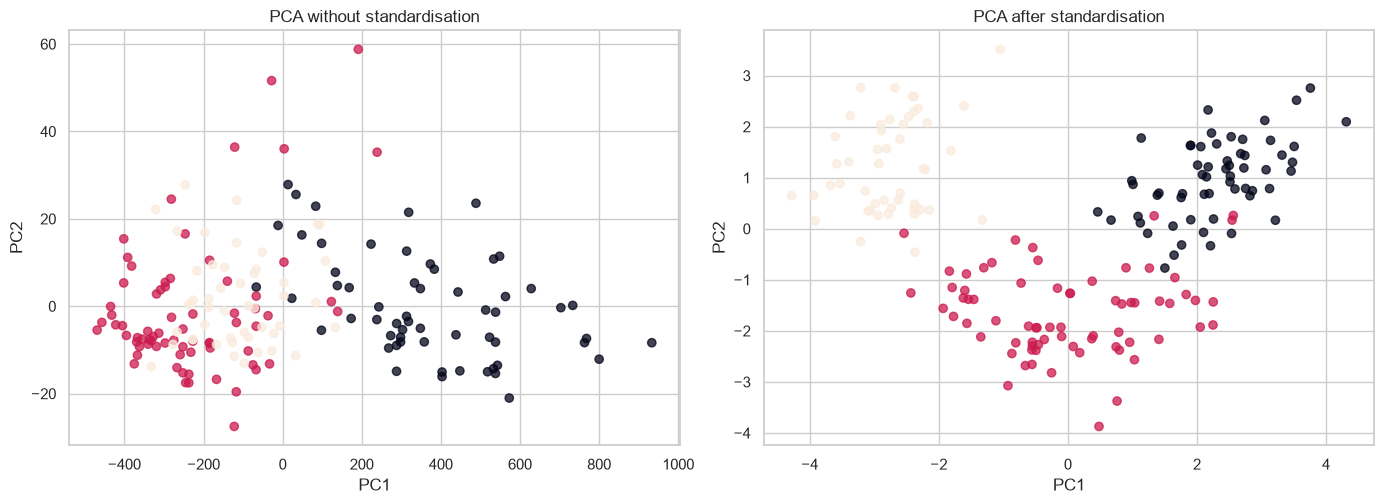

Explained variance, raw: [0.998 0.002]
Explained variance, scaled: [0.362 0.192]


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

axes[0].scatter(X_wine_raw_pca[:, 0], X_wine_raw_pca[:, 1], c=y_wine, alpha=0.75)
axes[0].set_title('PCA without standardisation')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

axes[1].scatter(X_wine_scaled_pca[:, 0], X_wine_scaled_pca[:, 1], c=y_wine, alpha=0.75)
axes[1].set_title('PCA after standardisation')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')

plt.tight_layout()
plt.show()

print('Explained variance, raw:', np.round(pca_raw.explained_variance_ratio_, 3))
print('Explained variance, scaled:', np.round(pca_scaled.explained_variance_ratio_, 3))

### Activity 2 — Explain what scaling changed

1. Which feature dominated raw PC1? proline 
2. Why did this happen? the values were really high compared to others
3. What does standardised PCA consider equally before learning the components? statistical variance of every feature
4. Is standardisation always mandatory? State one situation in which original units may be meaningful. no. when all features share the same unit of measurement

## 3. How many principal components should we keep?

We now use handwritten digit images.

Each 8×8 image becomes a vector of 64 pixel intensities. PCA can compress those 64 features into fewer latent coordinates.

Observations: 1797
Original features: 64
Image shape: (8, 8)


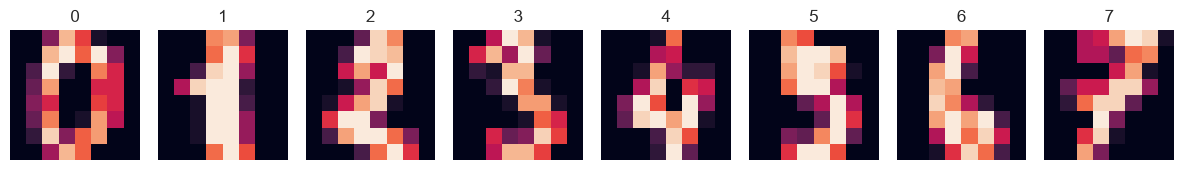

In [9]:
digits = load_digits()
X_digits = digits.data
y_digits = digits.target
images_digits = digits.images

print('Observations:', X_digits.shape[0])
print('Original features:', X_digits.shape[1])
print('Image shape:', images_digits.shape[1:])

fig, axes = plt.subplots(1, 8, figsize=(12, 2.2))
for axis, image, label in zip(axes, images_digits[:8], y_digits[:8]):
    axis.imshow(image)
    axis.set_title(str(label))
    axis.axis('off')
plt.tight_layout()
plt.show()

### Predict before viewing the curve

How many components do you expect to need for:

- approximately 80% of the variance? around 15
- approximately 90%? around 24
- approximately 95%? around 30

Do you expect 95% explained variance to require 95% of the original 64 features? Why or why not? No, because there is high spatial correlation between the pixels, the edges are almost always black

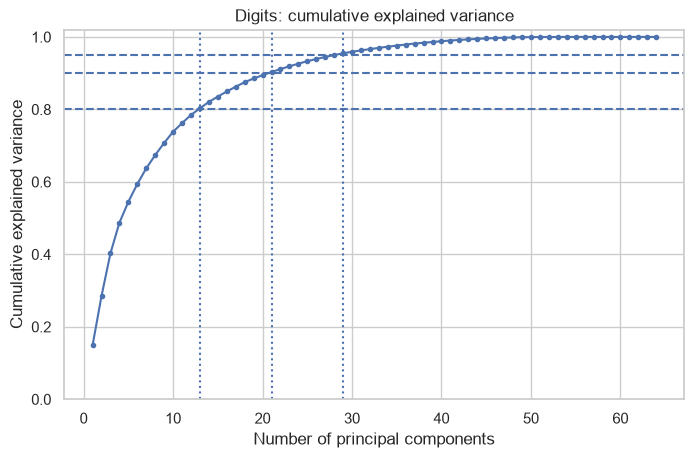

,minimum components
variance threshold,
0.80,13
0.90,21
0.95,29


In [10]:
pca_digits_full = PCA()
X_digits_pca_full = pca_digits_full.fit_transform(X_digits)

cumulative_variance = np.cumsum(pca_digits_full.explained_variance_ratio_)
thresholds = [0.80, 0.90, 0.95]
components_for_threshold = {
    threshold: int(np.argmax(cumulative_variance >= threshold) + 1)
    for threshold in thresholds
}

plt.figure(figsize=(8, 4.8))
plt.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', markersize=3)
for threshold in thresholds:
    plt.axhline(threshold, linestyle='--')
    plt.axvline(components_for_threshold[threshold], linestyle=':')
plt.xlabel('Number of principal components')
plt.ylabel('Cumulative explained variance')
plt.title('Digits: cumulative explained variance')
plt.ylim(0, 1.02)
plt.show()

pd.Series(
    components_for_threshold,
    name='minimum components',
).rename_axis('variance threshold').to_frame()

### Activity 3 — Choose a dimensionality for a stated purpose

Complete the recommendations:

> For strong compression with visible information loss, I would test approximately _____2 to 5_____ components.
>
> For retaining at least 90% of the variance, I need _____21_____ components.
>
> I would not choose the number only from the curve because _____the "elbow" or variance threshold reflects total feature variability, not specific information_____.

Why is explained variance a property of the features, not a direct measure of classification accuracy? it measures unsupervised data spread

### Reconstruct digits from different latent dimensions

Change `COMPONENT_COUNTS` only after viewing the first result.

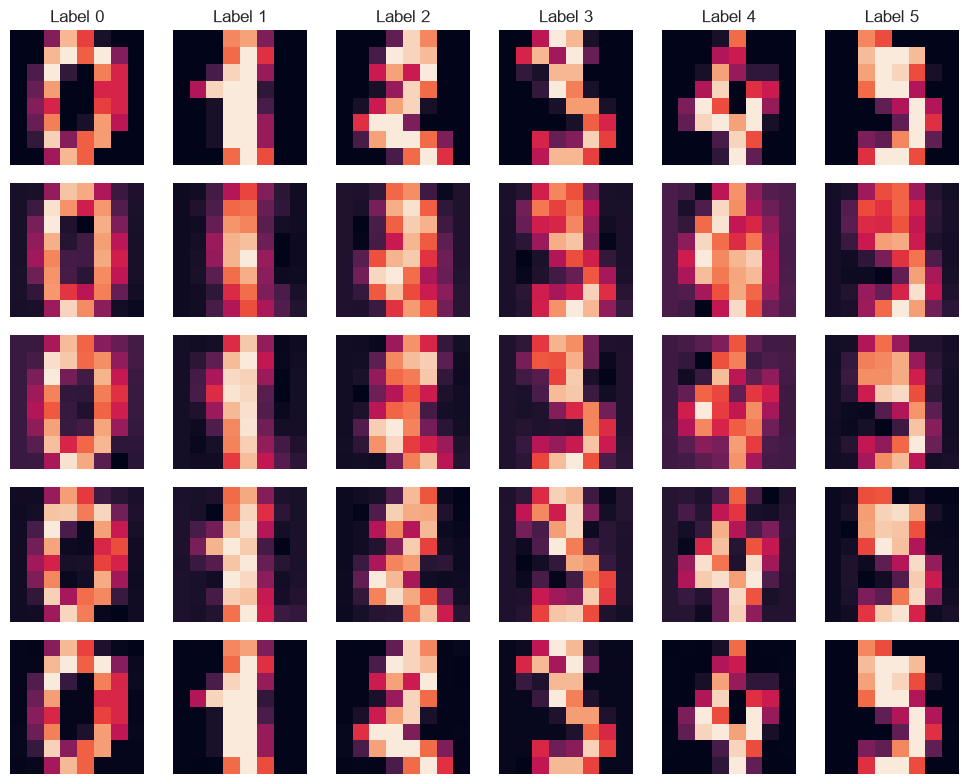

,components,explained variance,reconstruction MSE
0,5,0.545,8.542
1,15,0.835,3.092
2,30,0.959,0.768
3,50,1.000,0.009


In [11]:
COMPONENT_COUNTS = [5, 15, 30, 50]
SAMPLE_INDICES = [0, 1, 2, 3, 4, 5]

fig, axes = plt.subplots(
    len(COMPONENT_COUNTS) + 1,
    len(SAMPLE_INDICES),
    figsize=(10, 8),
)

for column, sample_index in enumerate(SAMPLE_INDICES):
    axes[0, column].imshow(images_digits[sample_index])
    axes[0, column].set_title(f'Label {y_digits[sample_index]}')
    axes[0, column].axis('off')

axes[0, 0].set_ylabel('Original')

reconstruction_rows = []

for row, component_count in enumerate(COMPONENT_COUNTS, start=1):
    pca_model = PCA(n_components=component_count)
    transformed = pca_model.fit_transform(X_digits)
    reconstructed = pca_model.inverse_transform(transformed)

    mse = np.mean((X_digits - reconstructed) ** 2)
    reconstruction_rows.append({
        'components': component_count,
        'explained variance': pca_model.explained_variance_ratio_.sum(),
        'reconstruction MSE': mse,
    })

    for column, sample_index in enumerate(SAMPLE_INDICES):
        axes[row, column].imshow(reconstructed[sample_index].reshape(8, 8))
        axes[row, column].axis('off')

    axes[row, 0].set_ylabel(f'{component_count} PCs')

plt.tight_layout()
plt.show()

pd.DataFrame(reconstruction_rows).round(3)

### Activity 4 — Connect numbers to visible information

1. At what component count do the digit identities become reliably recognisable? 15 or 30
2. Which details disappear first? sharp edges
3. Does the reconstruction MSE decrease monotonically? Why? yes 
4. Could a classifier still work well on a reconstruction that looks imperfect to a human? Yes

## 4. TruncatedSVD for sparse text data

PCA centres every feature, which can destroy sparsity. For a document–term matrix with many zeros, **TruncatedSVD** is often more practical because it operates without centring the matrix.

We will create a tiny bag-of-words dataset. The original words are high-dimensional observed features; the SVD components form a lower-dimensional latent representation.

In [12]:
documents = [
    'machine learning model data prediction',
    'classification model training data',
    'clustering features distance algorithm',
    'neural network model optimisation',
    'bread recipe flour yeast baking',
    'vegetable soup recipe cooking kitchen',
    'cake chocolate sugar baking recipe',
    'pasta sauce tomato cooking meal',
    'mountain hiking trail forest route',
    'travel train hotel city trip',
    'camping tent lake outdoor trip',
    'hiking map summit mountain route',
]

document_names = [
    'ML 1', 'ML 2', 'ML 3', 'ML 4',
    'Food 1', 'Food 2', 'Food 3', 'Food 4',
    'Travel 1', 'Travel 2', 'Travel 3', 'Travel 4',
]

vectorizer = CountVectorizer(stop_words='english')
X_text = vectorizer.fit_transform(documents)
terms = np.array(vectorizer.get_feature_names_out())

print('Document–term matrix shape:', X_text.shape)
print('Non-zero proportion:', round(X_text.nnz / (X_text.shape[0] * X_text.shape[1]), 3))

Document–term matrix shape: (12, 46)
Non-zero proportion: 0.103


### Predict the latent structure

How many broad themes do you expect?

Which words should receive strong weights in a component related to:

- machine learning, model, data, predicition...
- food, recipe, baking, cooking, sugar...
- travel or hiking? trip, mountain, route, trail...

In [13]:
svd_text = TruncatedSVD(n_components=3, random_state=RANDOM_STATE)
X_text_latent = svd_text.fit_transform(X_text)

component_rows = []
for component_index, component in enumerate(svd_text.components_, start=1):
    top_indices = np.argsort(np.abs(component))[::-1][:7]
    component_rows.append({
        'component': f'Component {component_index}',
        'top weighted terms': ', '.join(terms[top_indices]),
        'explained variance ratio': svd_text.explained_variance_ratio_[component_index - 1],
    })

latent_documents = pd.DataFrame(
    X_text_latent,
    index=document_names,
    columns=['Latent 1', 'Latent 2', 'Latent 3'],
)

display(pd.DataFrame(component_rows).round(3))
display(latent_documents.round(3))

,component,top weighted terms,explained variance ratio
0,Component 1,"route, mountain, hiking, forest, trail, summit...",0.133
1,Component 2,"recipe, baking, cooking, bread, yeast, flour, ...",0.110
2,Component 3,"model, data, prediction, machine, learning, tr...",0.109


,Latent 1,Latent 2,Latent 3
ML 1,-0.0,-0.000,1.908
ML 2,0.0,0.000,1.539
ML 3,0.0,0.000,-0.000
ML 4,-0.0,-0.000,1.083
Food 1,0.0,1.687,0.000
Food 2,0.0,1.373,0.000
Food 3,0.0,1.687,0.000
Food 4,0.0,0.488,0.000
Travel 1,2.0,-0.000,0.000
Travel 2,0.0,0.000,-0.000


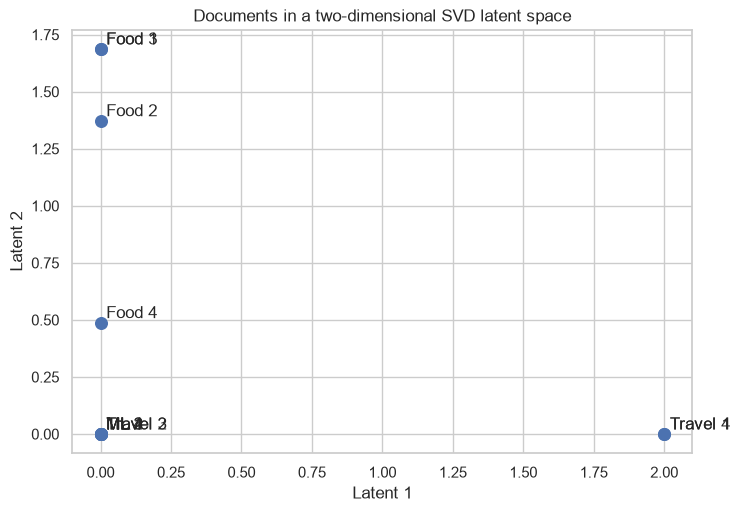

In [14]:
plt.figure(figsize=(8, 5.5))
plt.scatter(latent_documents['Latent 1'], latent_documents['Latent 2'], s=70)

for name, row in latent_documents.iterrows():
    plt.text(row['Latent 1'] + 0.02, row['Latent 2'] + 0.02, name)

plt.title('Documents in a two-dimensional SVD latent space')
plt.xlabel('Latent 1')
plt.ylabel('Latent 2')
plt.show()

### Activity 5 — Interpret a latent component cautiously

Choose one component and complete: Component 2

> This component appears related to _____food and cooking_____ because the strongly weighted terms include _____recipe, baking, cooking, bread, yeast and flour_____.
>
> It should not be called a hard topic label because _____it represents a continuous mathematical axis rather than a strict binary category_____.

Why may the sign of an SVD component change between implementations or runs without changing its underlying axis?

## 5. PCA versus t-SNE for two-dimensional visualisation

PCA is linear and preserves directions of large global variance. t-SNE is non-linear and focuses on preserving local neighbourhood probabilities.

Important caution:

> t-SNE is excellent for exploring local neighbourhoods, but distances between distant islands, island orientation, and apparent island size are not directly trustworthy.

We use a stratified subset of the digits data to keep the experiment fast.

In [15]:
_, X_digits_view, _, y_digits_view = train_test_split(
    X_digits,
    y_digits,
    test_size=900,
    stratify=y_digits,
    random_state=RANDOM_STATE,
)

X_digits_view_scaled = StandardScaler().fit_transform(X_digits_view)

pca_view = PCA(n_components=2, random_state=RANDOM_STATE)
embedding_pca = pca_view.fit_transform(X_digits_view_scaled)

PERPLEXITIES = [5, 30, 80]
embeddings_tsne = {}

for perplexity in PERPLEXITIES:
    model = TSNE(
        n_components=2,
        perplexity=perplexity,
        learning_rate='auto',
        init='pca',
        max_iter=700,
        random_state=RANDOM_STATE,
    )
    embeddings_tsne[perplexity] = model.fit_transform(X_digits_view_scaled)

### Predict before plotting

As perplexity increases, do you expect the embedding to emphasise very local or broader neighbourhoods? broader

Which visual properties do you expect to remain stable across several perplexities? cohesive clustering of highly distinctive digits

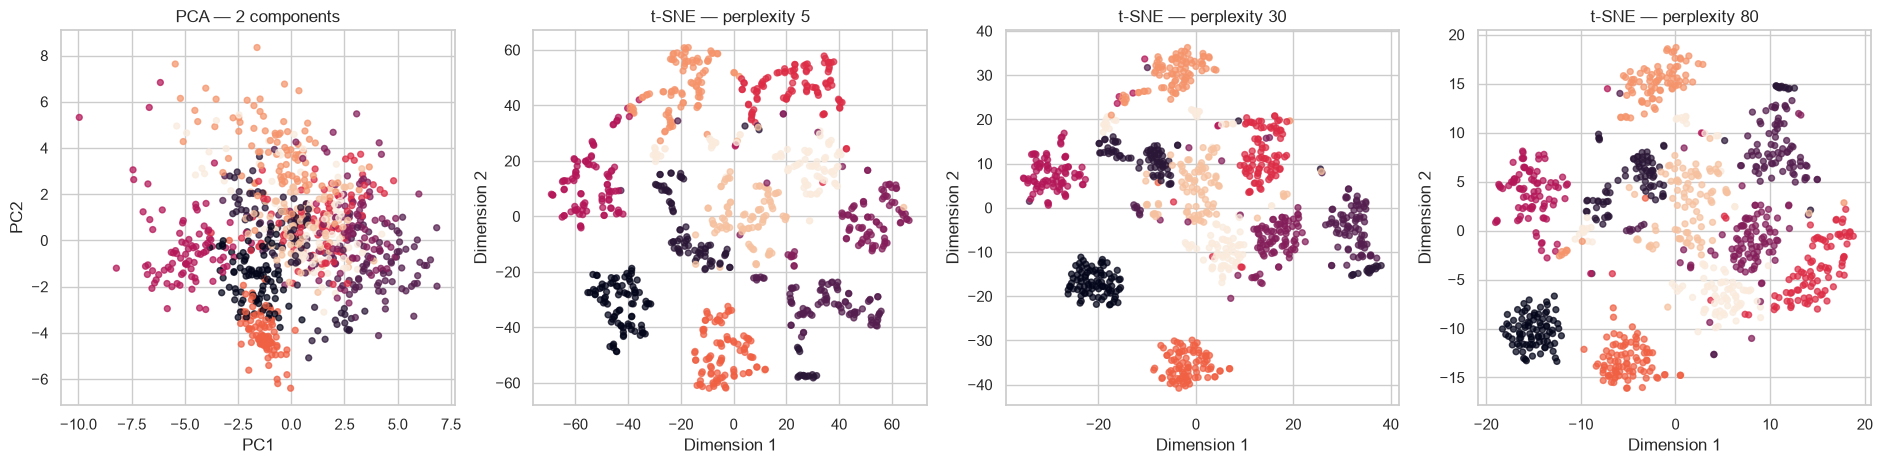

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.8))

axes[0].scatter(embedding_pca[:, 0], embedding_pca[:, 1], c=y_digits_view, s=18, alpha=0.72)
axes[0].set_title('PCA — 2 components')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

for axis, perplexity in zip(axes[1:], PERPLEXITIES):
    embedding = embeddings_tsne[perplexity]
    axis.scatter(embedding[:, 0], embedding[:, 1], c=y_digits_view, s=18, alpha=0.72)
    axis.set_title(f't-SNE — perplexity {perplexity}')
    axis.set_xlabel('Dimension 1')
    axis.set_ylabel('Dimension 2')

plt.tight_layout()
plt.show()

### Activity 6 — Separate observation from overclaim

Write one supported observation and one claim that would be too strong.

**Supported observation:**  As t-SNE perplexity increases from 5 to 30 to 80, the clusters contract into tighter islands.

**Too-strong claim:**  Because the dark cluster is positioned in the exact same bottom-left quadrant in both the perplexity 30 and perplexity 80 plots, its coordinate location proves a stable, objective global relationship to the other colors across different hyperparameters

Then answer:

1. Which digit classes form stable local groups across settings? dark cluster, orange cluster and red cluster
2. Which relationships change substantially? 
3. Why can two distant islands in t-SNE not automatically be interpreted as very dissimilar classes?

### Audit local-neighbourhood preservation

`trustworthiness` asks whether points that appear close in the embedding were also reasonably close in the original feature space.

It is not a complete measure of embedding quality, but it provides evidence beyond visual appearance.

In [17]:
trust_rows = [{
    'representation': 'PCA — 2 components',
    'trustworthiness': trustworthiness(
        X_digits_view_scaled,
        embedding_pca,
        n_neighbors=10,
    ),
}]

for perplexity, embedding in embeddings_tsne.items():
    trust_rows.append({
        'representation': f't-SNE — perplexity {perplexity}',
        'trustworthiness': trustworthiness(
            X_digits_view_scaled,
            embedding,
            n_neighbors=10,
        ),
    })

trust_table = pd.DataFrame(trust_rows).sort_values('trustworthiness', ascending=False)
trust_table.round(3)

,representation,trustworthiness
2,t-SNE — perplexity 30,0.976
3,t-SNE — perplexity 80,0.973
1,t-SNE — perplexity 5,0.971
0,PCA — 2 components,0.823


### Verification checkpoint

1. Does the numerical audit agree with your visual impression? yes, it shows a big gap between PCA and all three t-SNE
2. Can a high trustworthiness score prove that all global distances are correct? No, it was configured with 10 neighbours
3. Why should several parameter settings be inspected rather than reporting one attractive t-SNE plot? Because t-SNE can create visual results that look attractive but are misleading

## 6. Optional UMAP comparison

UMAP is another non-linear embedding method. Two influential parameters are:

- `n_neighbors`: the local-versus-broader neighbourhood scale,
- `min_dist`: how tightly points may be packed in the embedding.

The next cell runs only when `umap-learn` is installed.

In Google Colab, install it once with:

```python
%pip install -q umap-learn
```

Then restart or rerun the import cell if necessary.

In [21]:
try:
    import umap
    UMAP_AVAILABLE = True
except ImportError:
    UMAP_AVAILABLE = False
    print('UMAP is not installed. Run: %pip install -q umap-learn')

C:\Users\kov0426\AppData\Roaming\Python\Python314\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


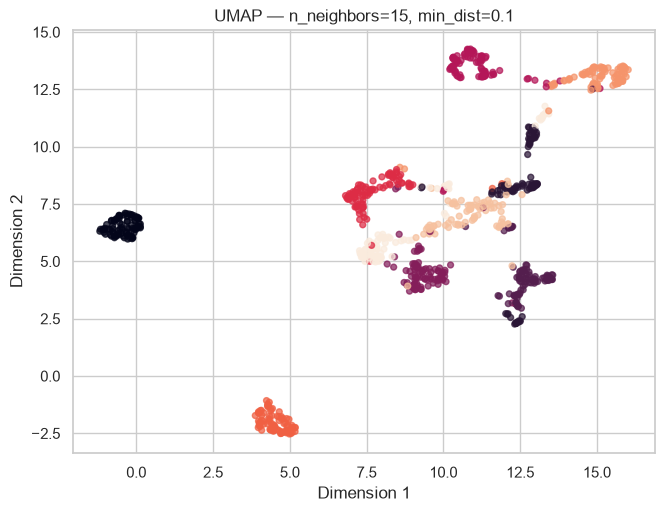

Trustworthiness: 0.97


In [27]:
UMAP_N_NEIGHBORS = 15
UMAP_MIN_DIST = 0.10

if UMAP_AVAILABLE:
    umap_model = umap.UMAP(
        n_components=2,
        n_neighbors=UMAP_N_NEIGHBORS,
        min_dist=UMAP_MIN_DIST,
        random_state=RANDOM_STATE,
    )
    embedding_umap = umap_model.fit_transform(X_digits_view_scaled)

    plt.figure(figsize=(7.5, 5.5))
    plt.scatter(embedding_umap[:, 0], embedding_umap[:, 1], c=y_digits_view, s=18, alpha=0.72)
    plt.title(
        f'UMAP — n_neighbors={UMAP_N_NEIGHBORS}, '
        f'min_dist={UMAP_MIN_DIST}'
    )
    plt.xlabel('Dimension 1')
    plt.ylabel('Dimension 2')
    plt.show()

    print(
        'Trustworthiness:',
        round(
            trustworthiness(
                X_digits_view_scaled,
                embedding_umap,
                n_neighbors=10,
            ),
            3,
        ),
    )
else:
    print('UMAP section skipped. PCA and t-SNE results remain available.')

### Optional interpretation

If UMAP ran, compare it with t-SNE:

- Which local groups appear stable in both methods? dark and orange clusters
- Which global relationships differ? in t-SNE the clusters form distinct islands but in UMAP they form a connected, continuous branching structure
- What changes when `n_neighbors` is increased? the points will pull closer together into smoother, more compact shapes
- Why should agreement between two methods increase confidence but still not prove a cluster structure? if two methods produce the same groups it strongly suggests they represent genuine patterns

## 7. Dimensionality reduction inside a modelling pipeline

When PCA is used before a supervised model, it must be fitted **inside** the training procedure.

Incorrect workflow:

1. fit PCA on the complete dataset,
2. cross-validate a classifier on the already transformed data.

Leakage-safe workflow:

1. each cross-validation fold fits scaling and PCA only on its training part,
2. the fitted transformation is applied to that fold's validation part.

A scikit-learn `Pipeline` enforces this sequence.

In [28]:
X_wine_model = wine.data

y_wine_model = wine.target

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

baseline_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=3000)),
])

pca_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('pca', PCA(n_components=0.90)),
    ('classifier', LogisticRegression(max_iter=3000)),
])

baseline_scores = cross_validate(
    baseline_pipeline,
    X_wine_model,
    y_wine_model,
    cv=cv,
    scoring='accuracy',
    return_train_score=True,
)

pca_scores = cross_validate(
    pca_pipeline,
    X_wine_model,
    y_wine_model,
    cv=cv,
    scoring='accuracy',
    return_train_score=True,
)

pipeline_comparison = pd.DataFrame([
    {
        'pipeline': 'Scaled logistic regression',
        'mean train accuracy': baseline_scores['train_score'].mean(),
        'mean validation accuracy': baseline_scores['test_score'].mean(),
        'validation standard deviation': baseline_scores['test_score'].std(),
    },
    {
        'pipeline': 'Scaling + PCA(90%) + logistic regression',
        'mean train accuracy': pca_scores['train_score'].mean(),
        'mean validation accuracy': pca_scores['test_score'].mean(),
        'validation standard deviation': pca_scores['test_score'].std(),
    },
])

pipeline_comparison.round(3)

,pipeline,mean train accuracy,mean validation accuracy,validation standard deviation
0,Scaled logistic regression,1.0,0.983,0.014
1,Scaling + PCA(90%) + logistic regression,1.0,0.978,0.011


### Activity 7 — Interpret the modelling trade-off

1. Did PCA improve, preserve, or reduce validation accuracy? it slightly reduced mean validation accuracy, however the standard deviation is well within
2. Why might a lower-dimensional model still be useful even without higher accuracy? faster training, reduced storage, mitigation of the curse of dimensionality
3. Why is t-SNE not used in this pipeline? no native .transform() method, destruction of global structure
4. What information would you need before claiming that PCA made the model “better”? inference latency, memory profiles, model robustness

## Guided AI study activity — challenge a latent-space interpretation

First write your own interpretation of one t-SNE or UMAP plot.

**My initial interpretation:**  

Then use this prompt:

```text
Act as a cautious dimensionality-reduction tutor.
Do not rewrite my interpretation and do not tell me what the plot means.
Ask me exactly three short questions, one at a time:

1. Which relationships in this embedding are local, and which may be visually misleading?
2. What parameter, random seed, or alternative method should I compare?
3. What evidence from the original feature space or a numerical audit supports my claim?

Wait for my answer after each question.
```

Close the chat and record only:

**One useful question from AI:**  

**One sentence I revised:**  

**What evidence now supports the revised sentence:**  

Do not paste the complete conversation.

## 8. Assessed task — Latent-space audit (2 points)

Prepare a concise audit of dimensionality reduction on the digits data.

Use the prepared code and change at least **two** settings:

- one PCA component count,
- one t-SNE perplexity or random seed,
- optionally one UMAP `n_neighbors` or `min_dist` value.

Submit:

1. **Purpose:** compression, visualisation, or downstream modelling.
2. **PCA choice:** selected number of components and evidence from explained variance or reconstruction.
3. **Embedding comparison:** PCA plus t-SNE, and optionally UMAP.
4. **Stable observation:** one pattern visible under more than one defensible setting or method.
5. **Numerical audit:** trustworthiness or reconstruction MSE.
6. **Limitation:** one conclusion that the 2D plot cannot support.
7. **Recommendation:** which representation you would use for the stated purpose.
8. **AI note:** if AI was used, state one question it asked and one claim you independently verified.

### Marking

| Criterion | Points |
|---|---:|
| PCA dimensionality is justified with evidence | 0.50 |
| Embedding comparison uses more than one setting or method | 0.50 |
| Interpretation is cautious and supported | 0.50 |
| Numerical audit, limitation, and recommendation are coherent | 0.50 |

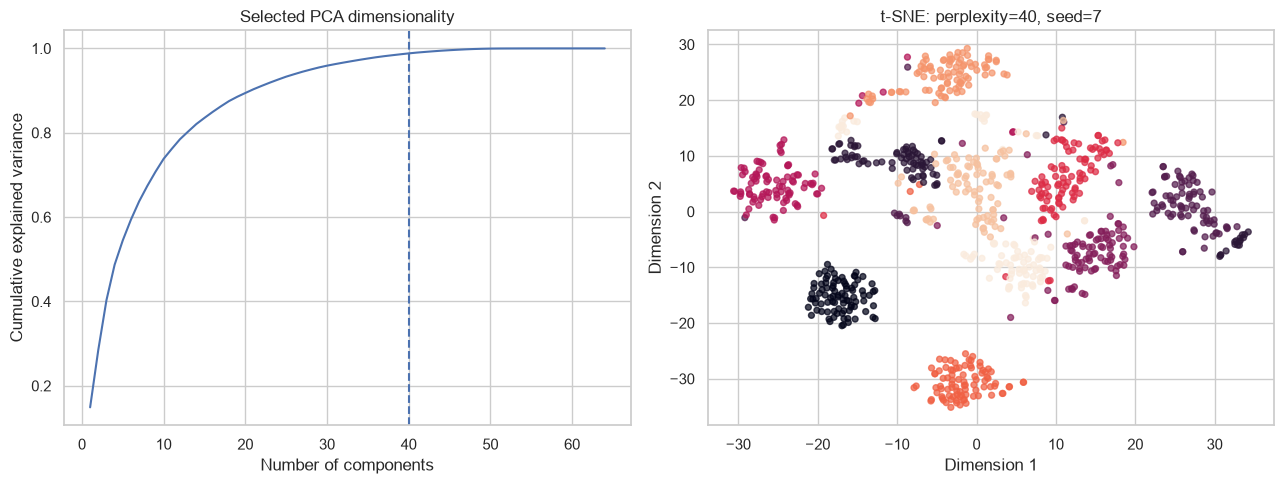

PCA components            40.000
PCA explained variance     0.988
PCA reconstruction MSE     0.221
t-SNE trustworthiness      0.978
dtype: float64

In [32]:
# Change at least TWO clearly marked settings.

AUDIT_PCA_COMPONENTS = 20
AUDIT_TSNE_PERPLEXITY = 40
AUDIT_TSNE_SEED = 7

pca_audit_model = PCA(n_components=AUDIT_PCA_COMPONENTS)
X_audit_latent = pca_audit_model.fit_transform(X_digits)
X_audit_reconstructed = pca_audit_model.inverse_transform(X_audit_latent)

audit_reconstruction_mse = np.mean(
    (X_digits - X_audit_reconstructed) ** 2
)

tsne_audit_model = TSNE(
    n_components=2,
    perplexity=AUDIT_TSNE_PERPLEXITY,
    learning_rate='auto',
    init='pca',
    max_iter=700,
    random_state=AUDIT_TSNE_SEED,
)
embedding_tsne_audit = tsne_audit_model.fit_transform(X_digits_view_scaled)

audit_trustworthiness = trustworthiness(
    X_digits_view_scaled,
    embedding_tsne_audit,
    n_neighbors=10,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance,
)
axes[0].axvline(AUDIT_PCA_COMPONENTS, linestyle='--')
axes[0].set_title('Selected PCA dimensionality')
axes[0].set_xlabel('Number of components')
axes[0].set_ylabel('Cumulative explained variance')

axes[1].scatter(
    embedding_tsne_audit[:, 0],
    embedding_tsne_audit[:, 1],
    c=y_digits_view,
    s=18,
    alpha=0.72,
)
axes[1].set_title(
    f't-SNE: perplexity={AUDIT_TSNE_PERPLEXITY}, '
    f'seed={AUDIT_TSNE_SEED}'
)
axes[1].set_xlabel('Dimension 1')
axes[1].set_ylabel('Dimension 2')

plt.tight_layout()
plt.show()

pd.Series({
    'PCA components': AUDIT_PCA_COMPONENTS,
    'PCA explained variance': pca_audit_model.explained_variance_ratio_.sum(),
    'PCA reconstruction MSE': audit_reconstruction_mse,
    't-SNE trustworthiness': audit_trustworthiness,
}).round(3)

### Your latent-space audit

**Purpose:**  Visual exploration and structural discovery of handwritten digit groups to identify which digit classes share a highly overlapping structural feature space and which are naturally distinct.

**PCA choice and evidence:**  

**Methods/settings compared:**  

**Stable observation:**  

**Numerical audit:**  

**Unsupported conclusion I avoided:**  

**Recommendation:**  

**Optional verified AI note:**

# End-of-lab self-check

Before finishing, check that you can:

- [ ] explain PC1 as a direction of maximum variance,
- [ ] explain why component signs may flip,
- [ ] distinguish projection from reconstruction,
- [ ] explain how scaling changes PCA,
- [ ] use cumulative explained variance without treating it as the only criterion,
- [ ] relate component count to visible reconstruction quality,
- [ ] explain why TruncatedSVD is useful for sparse matrices,
- [ ] distinguish PCA from t-SNE and UMAP,
- [ ] state which visual properties of t-SNE are unreliable,
- [ ] audit an embedding with another setting, method, or numerical measure,
- [ ] place PCA inside a leakage-safe pipeline,
- [ ] revise an embedding claim after evidence-based questions.

Exercise 9 will focus on systematic hyperparameter optimisation with Optuna.